# CIFAR-10: convolutional image classification

A two-block convolutional network is evaluated on ten object classes. The analysis records the dataset split, training behaviour, class-level errors and predictions for test indices 16 and 1–15.

The fresh training run and the historical outputs in the source notebook are reported separately. This notebook reproduces evaluation from the accompanying model snapshot, whose SHA-256 digest is checked. If the snapshot is absent, or `retrain` is enabled, the same architecture is trained from scratch. Training remains stochastic across software and hardware configurations.

## Data and preprocessing

CIFAR-10 contains 60,000 RGB images at 32 × 32 pixels: 50,000 training and 10,000 test examples. The first 10,000 training records are reserved for validation; the remaining 40,000 are used for fitting. Pixels are scaled to [0, 1] as float32, and labels are one-hot encoded. No augmentation is applied. The first source training image is a frog, correcting the reference caption.

Dataset: https://www.cs.toronto.edu/~kriz/cifar.html (accessed 14 October 2026). The archive used for this run was obtained from the [Zenodo mirror](https://zenodo.org/records/10089977) and verified against the official MD5 digest `c58f30108f718f92721af3b95e74349a`; Keras additionally validates its SHA-256 digest when loading the cached archive.

In [1]:
from pathlib import Path
import hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import classification_report, confusion_matrix
from IPython.display import display

keras.utils.set_random_seed(112)
np.random.seed(888)
names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
(x_all_raw,y_all),(x_test_raw,y_test)=keras.datasets.cifar10.load_data()
x_val=x_all_raw[:10000].astype('float32')/255
x_train=x_all_raw[10000:].astype('float32')/255
x_test=x_test_raw.astype('float32')/255
y_val=keras.utils.to_categorical(y_all[:10000],10)
y_train=keras.utils.to_categorical(y_all[10000:],10)
y_test_cat=keras.utils.to_categorical(y_test,10)
print('TensorFlow:',tf.__version__,'Keras:',keras.__version__,'NumPy:',np.__version__)
display(pd.DataFrame({'Partition':['Training','Validation','Test'],'Images':[len(x_train),len(x_val),len(x_test)],'Image shape':[str(x_train.shape[1:])]*3}))
assert x_train.shape==(40000,32,32,3)
assert np.array_equal(np.bincount(y_test.ravel()),np.repeat(1000,10))
assert names[int(y_all[0,0])]=='frog'


Partition,Images,Image shape
Training,40000,"(32, 32, 3)"
Validation,10000,"(32, 32, 3)"
Test,10000,"(32, 32, 3)"


TensorFlow: 2.20.0 Keras: 3.15.1 NumPy: 2.5.4


## Architecture and training

The network uses two valid 4 × 4 convolutions with 32 ReLU filters, each followed by 2 × 2 max pooling. Flattened features feed a 256-unit ReLU layer and a ten-unit softmax layer. The total is 225,610 trainable parameters.

Adam uses learning rate 0.001 and categorical cross-entropy. Training runs for at most 25 epochs, in batches of 32. Early stopping monitors validation loss with patience two and retains the final weights (`restore_best_weights=False`), matching the reference policy. An explicit input layer and `argmax` predictions replace outdated API usage.

The snapshot and its recorded history were produced by an executed training run. Loading the snapshot below preserves those exact weights for repeatable evaluation; a new training run replaces the history with its own measurements.

In [2]:
def make_model():
    model=keras.Sequential([
        keras.Input(shape=(32,32,3)),
        keras.layers.Conv2D(32,(4,4),activation='relu'),
        keras.layers.MaxPool2D((2,2)),
        keras.layers.Conv2D(32,(4,4),activation='relu'),
        keras.layers.MaxPool2D((2,2)),
        keras.layers.Flatten(),
        keras.layers.Dense(256,activation='relu'),
        keras.layers.Dense(10,activation='softmax')])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),loss='categorical_crossentropy',metrics=['accuracy'])
    return model

retrain=False
model_path=Path('module-4-machine-learning_cnn-model-activity.keras')
recorded_history={'accuracy': [0.43630000948905945, 0.5500749945640564, 0.6015999913215637, 0.6392999887466431, 0.6704750061035156, 0.7002500295639038, 0.724049985408783], 'loss': [1.5583744049072266, 1.266348958015442, 1.1262283325195312, 1.0259455442428589, 0.9408760666847229, 0.8618056774139404, 0.7956073880195618], 'val_accuracy': [0.5236999988555908, 0.5781000256538391, 0.6110000014305115, 0.619700014591217, 0.6298999786376953, 0.6291999816894531, 0.6370000243186951], 'val_loss': [1.3216253519058228, 1.180350422859192, 1.1109098196029663, 1.085445761680603, 1.0770056247711182, 1.1011725664138794, 1.1177186965942383]}
expected_sha256='358c1eece75b8efb75495964ecd92fd07ea641fb45a3fde82a9f63fc56aae774'
if model_path.exists() and not retrain:
    assert hashlib.sha256(model_path.read_bytes()).hexdigest()==expected_sha256, 'Model snapshot differs from the recorded training run.'
    model=keras.models.load_model(model_path)
    history=recorded_history
    print('Verified trained snapshot loaded; history describes its original training run.')
else:
    model=make_model()
    fitted=model.fit(x_train,y_train,validation_data=(x_val,y_val),batch_size=32,epochs=25,callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=2,restore_best_weights=False)],verbose=2)
    history=fitted.history
    print('New training run completed.')
assert model.count_params()==225610
display(pd.DataFrame([{'Layer':layer.name,'Output shape':str(layer.output.shape),'Parameters':layer.count_params()} for layer in model.layers]))
history_table=pd.DataFrame(history)
history_table.index=np.arange(1,len(history_table)+1)
history_table.index.name='Epoch'
display(history_table.reset_index().round(6))
print('Lowest validation loss at epoch:',int(np.argmin(history['val_loss']))+1)


Layer,Output shape,Parameters
conv2d,"(None, 29, 29, 32)",1568
max_pooling2d,"(None, 14, 14, 32)",0
conv2d_1,"(None, 11, 11, 32)",16416
max_pooling2d_1,"(None, 5, 5, 32)",0
flatten,"(None, 800)",0
dense,"(None, 256)",205056
dense_1,"(None, 10)",2570


Epoch,accuracy,loss,val_accuracy,val_loss
1,0.436300,1.558374,0.5237,1.321625
2,0.550075,1.266349,0.5781,1.180350
3,0.601600,1.126228,0.6110,1.110910
4,0.639300,1.025946,0.6197,1.085446
5,0.670475,0.940876,0.6299,1.077006
6,0.700250,0.861806,0.6292,1.101173
7,0.724050,0.795607,0.6370,1.117719


Verified trained snapshot loaded; history describes its original training run.
Lowest validation loss at epoch: 5


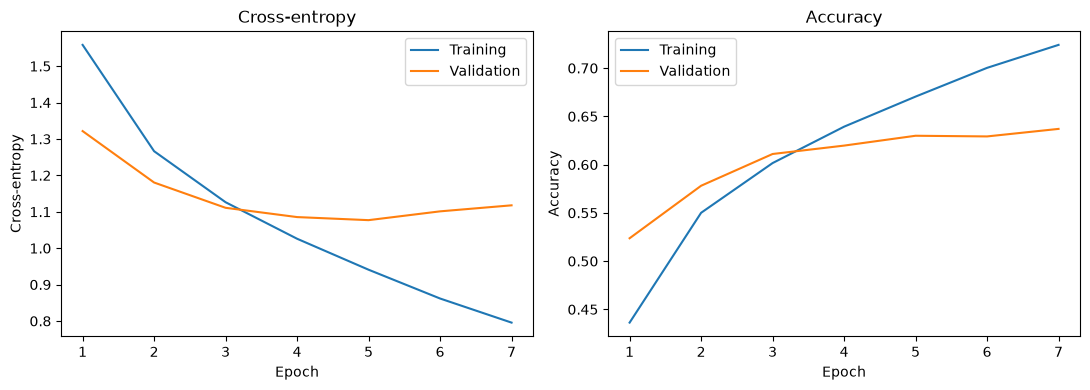

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
epochs=np.arange(1,len(history['loss'])+1)
for ax,metric,title in zip(axes,['loss','accuracy'],['Cross-entropy','Accuracy']):
    ax.plot(epochs,history[metric],label='Training')
    ax.plot(epochs,history['val_'+metric],label='Validation')
    ax.set(xlabel='Epoch',ylabel=title,title=title)
    ax.legend()
plt.tight_layout();plt.show()


## Independent test evaluation

The test set is kept out of model fitting and early stopping. The supplied notebook records nine epochs, test accuracy 67.03% and test loss 1.0768; those are historical outputs, not measurements from the current snapshot. The following results are recomputed from the trained snapshot. Precision, recall and F1 complement accuracy by exposing uneven performance across classes.

Run,Test accuracy,Test loss
Supplied notebook: saved outputs,0.6703,1.076809
Fresh model: recomputed evaluation,0.6304,1.119507


Class / average,precision,recall,f1-score,support
airplane,0.7667,0.6540,0.7059,1000.0000
automobile,0.7755,0.7080,0.7402,1000.0000
bird,0.5121,0.5520,0.5313,1000.0000
cat,0.3835,0.6120,0.4715,1000.0000
deer,0.5939,0.5440,0.5678,1000.0000
dog,0.5875,0.3860,0.4659,1000.0000
frog,0.7140,0.7390,0.7263,1000.0000
horse,0.7010,0.6940,0.6975,1000.0000
ship,0.8176,0.6680,0.7353,1000.0000
truck,0.6524,0.7470,0.6965,1000.0000


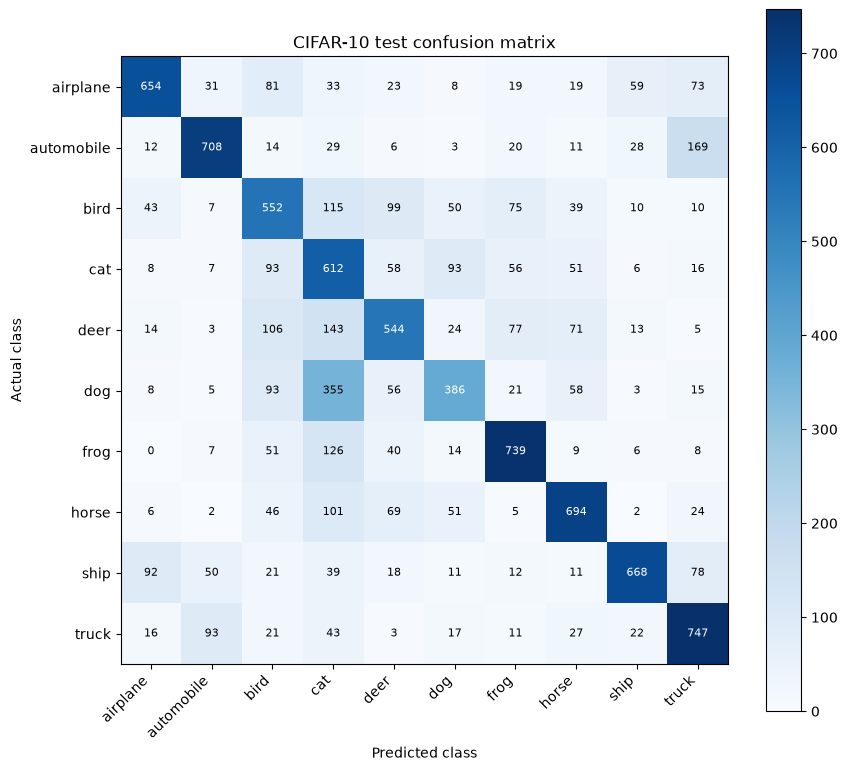

In [4]:
test_loss,test_accuracy=model.evaluate(x_test,y_test_cat,verbose=0)
probabilities=model.predict(x_test,verbose=0)
predicted=probabilities.argmax(axis=1)
truth=y_test.ravel()
cm=confusion_matrix(truth,predicted,labels=np.arange(10))
assert int(np.trace(cm))==int(np.sum(truth==predicted))
assert np.isclose(test_accuracy,np.mean(truth==predicted),atol=1e-6)
assert np.allclose(probabilities.sum(axis=1),1,atol=1e-5)
display(pd.DataFrame([{'Run':'Supplied notebook: saved outputs','Test accuracy':0.6703,'Test loss':1.0768086910247803},{'Run':'Fresh model: recomputed evaluation','Test accuracy':test_accuracy,'Test loss':test_loss}]))
report=classification_report(truth,predicted,target_names=names,output_dict=True,zero_division=0)
display(pd.DataFrame(report).transpose().round(4).reset_index(names='Class / average'))
fig,ax=plt.subplots(figsize=(9,8))
im=ax.imshow(cm,cmap='Blues')
ax.set(xticks=np.arange(10),yticks=np.arange(10),xticklabels=names,yticklabels=names,xlabel='Predicted class',ylabel='Actual class',title='CIFAR-10 test confusion matrix')
plt.setp(ax.get_xticklabels(),rotation=45,ha='right')
for i in range(10):
    for j in range(10):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black',fontsize=8)
fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()


## Image-level predictions

The same index selects the displayed image, model input and ground-truth label. Index 16 is followed by all indices 1–15, preventing selection only of successful examples. The top softmax score is not a calibrated probability of correctness. This small selection illustrates decisions; the full test set provides the performance estimate.

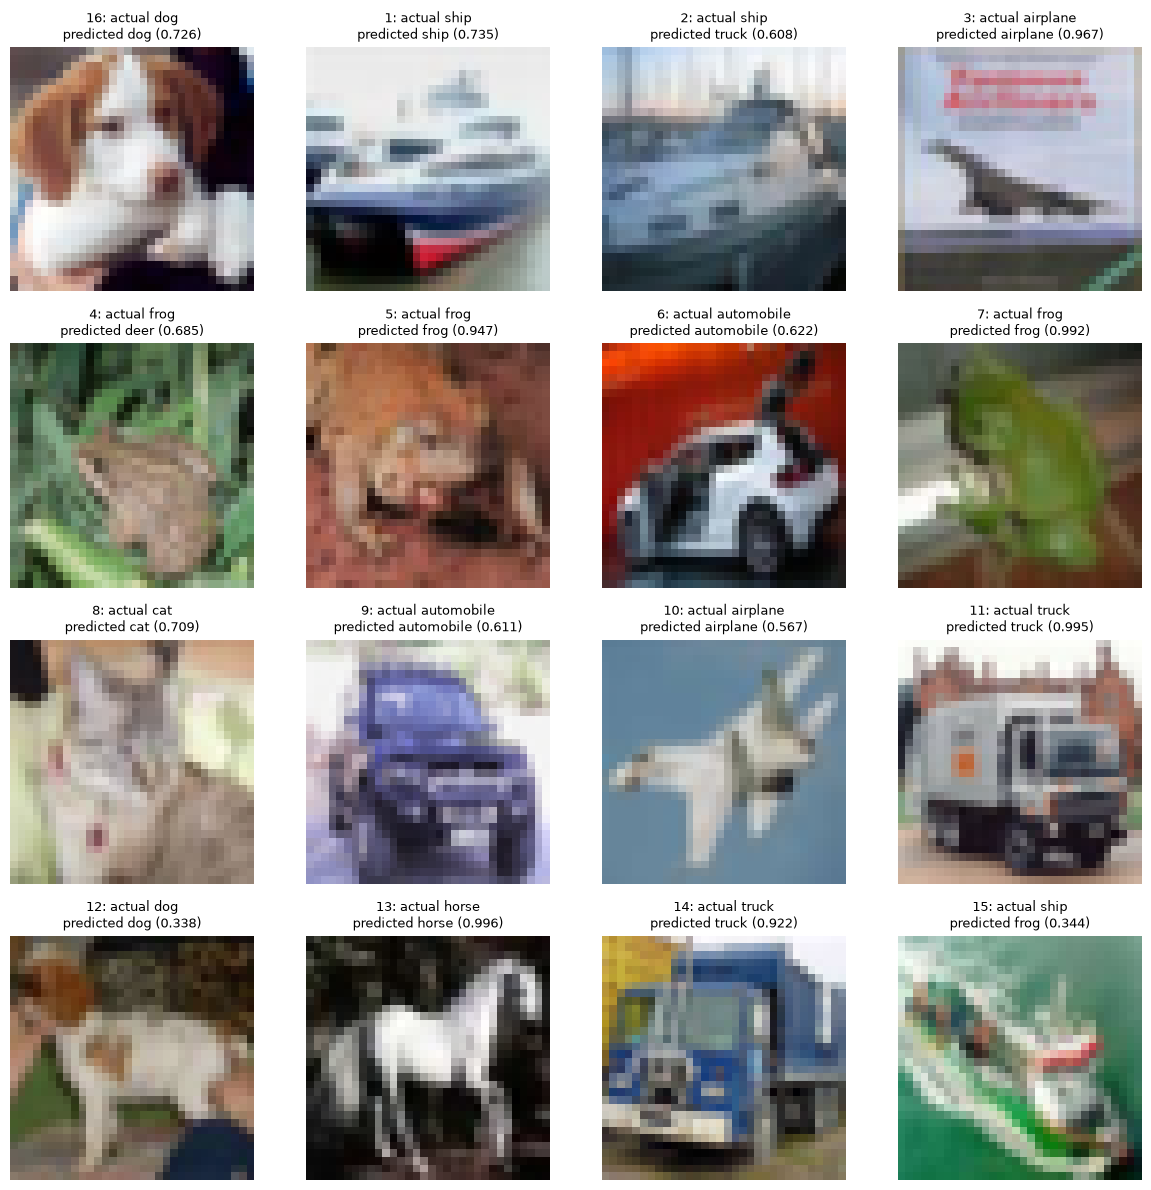

Index,Actual,Predicted,Top score,Correct
16,dog,dog,0.7259,True
1,ship,ship,0.7347,True
2,ship,truck,0.6083,False
3,airplane,airplane,0.9669,True
4,frog,deer,0.6848,False
5,frog,frog,0.9474,True
6,automobile,automobile,0.6223,True
7,frog,frog,0.9915,True
8,cat,cat,0.7088,True
9,automobile,automobile,0.6109,True


Alternative indices correct: 12 of 15


In [5]:
indices=[16,*range(1,16)]
rows=[]
fig,axes=plt.subplots(4,4,figsize=(12,12))
for ax,index in zip(axes.ravel(),indices):
    scores=model.predict(x_test[index:index+1],verbose=0)[0]
    label=int(scores.argmax());actual=int(truth[index])
    assert label==int(predicted[index])
    rows.append({'Index':index,'Actual':names[actual],'Predicted':names[label],'Top score':float(scores[label]),'Correct':label==actual})
    ax.imshow(x_test_raw[index]);ax.axis('off')
    ax.set_title(f'{index}: actual {names[actual]}\npredicted {names[label]} ({scores[label]:.3f})',fontsize=9)
plt.tight_layout();plt.show()
display(pd.DataFrame(rows).round(4))
print('Alternative indices correct:',sum(row['Correct'] for row in rows[1:]),'of 15')


## Interpretation and responsible use

The recorded model achieved 63.04% test accuracy after seven epochs, compared with 67.03% in the supplied notebook’s saved outputs. Validation loss increased from 1.0770 at epoch five to 1.1177 at epoch seven while training loss fell from 0.9409 to 0.7956, consistent with overfitting. Dog recall was 38.6%, and 355 dogs were classified as cats. Index 16 and 12 of the 15 alternative images were classified correctly. These observations support examining errors and the stopping policy, rather than treating one overall score as a complete evaluation. Retaining the last weights after early stopping is a deliberate property of this baseline; restoring the best validation-loss weights would be a separate configuration. Further comparisons should use a fixed validation protocol and repeated initialisations before final testing.

Low-resolution object images provide limited evidence about deployment conditions. The model always chooses among ten known classes and has no explicit rejection mechanism for unfamiliar inputs. Neither class balance nor overall accuracy establishes demographic fairness.

Wall (2019) discusses false facial matches, surveillance and unequal performance. Those concerns do not make CIFAR-10 a facial recognition benchmark: object classification, gender classification and identity matching are different tasks. Dataset documentation should make provenance and intended uses explicit (Gebru et al., 2021), while lifecycle audits should establish responsibility for decisions and failures (Raji et al., 2020). Improved accuracy alone cannot establish that a surveillance use is appropriate.

## Provenance

Adapted from `Unit09 Ex1 Convolutional Neural Networks (CNN) - Object Recognition.ipynb`. The data split, architecture and stopping policy are retained. Changes include modern Keras APIs, float32 preprocessing, explicit seed control, consistent image-index selection, class-level checks and recorded model provenance. Saved outputs were generated by executing the analysis against the trained model. Analysis and editorial preparation used AI assistance.


## References

Gebru, T., Morgenstern, J., Vecchione, B., Vaughan, J.W., Wallach, H., Daumé III, H. and Crawford, K. (2021) ‘Datasheets for datasets’, *Communications of the ACM*, 64(12), pp. 86–92. Available at: https://doi.org/10.1145/3458723 (Accessed: 14 October 2026).

LeCun, Y., Bottou, L., Bengio, Y. and Haffner, P. (1998) ‘Gradient-based learning applied to document recognition’, *Proceedings of the IEEE*, 86(11), pp. 2278–2324. Available at: https://doi.org/10.1109/5.726791 (Accessed: 14 October 2026).

Raji, I.D., Smart, A., White, R.N., Mitchell, M., Gebru, T., Hutchinson, B., Smith-Loud, J., Theron, D. and Barnes, P. (2020) ‘Closing the AI accountability gap: defining an end-to-end framework for internal algorithmic auditing’, *Proceedings of the 2020 Conference on Fairness, Accountability, and Transparency*. New York: ACM, pp. 33–44. Available at: https://doi.org/10.1145/3351095.3372873 (Accessed: 14 October 2026).

Wall, M. (2019) ‘Biased and wrong? Facial recognition tech in the dock’, *BBC News*, 8 July. Available at: https://www.bbc.co.uk/news/business-48842750 (Accessed: 14 October 2026).